In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Preamble

In [1]:
n = 1001
h_bar = 1.054 * 10**-34  # Planck's constant in J*s
e = 1.6 * 10**-19  # elementary charge in C
c0 = 3 * 10**8  # speed of light in m/s

# Taking $O_2$ molecule
With $\omega = 2\pi c_0 \bar{\nu}\quad$ and $\quad\bar{\nu}= 1580.161 cm^{-1}$

In [16]:
# u = 1.660538921 * 10**(-27)  # atomic mass unit in kg
# m_O = 15.999*u  # Mass of oxygen atom in kg
# reduced_m = m_O*m_O/(m_O + m_O)  # Reduced mass for oxygen-oxygen system 

# nu_bar = 1580.161  #(cm^-1) harmonic spectroscopic constant National Institute of Standards and Technology (NIST) 2022
# omega = 2* np.pi * c0 * nu_bar * 100  # angular frequency in rad/s

# a_osc = np.sqrt(h_bar / (reduced_m * omega))

# xmin = -5 * a_osc
# xmax = 5 * a_osc
# x = np.linspace(xmin, xmax, n)
# delta_x = x[1] - x[0]
# c = (h_bar**2) / (2*reduced_m *e*delta_x**2)

# print("c =", c,", xmin =", xmin,", xmax =", xmax,", delta_x =", delta_x,", n =", n)

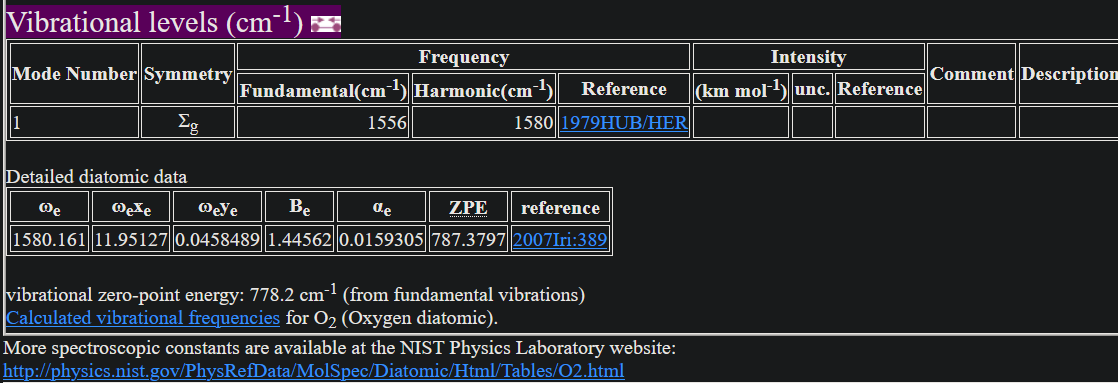

In [3]:
reduced_m = 1.67 * 10**(-27)  # atomic mass unit in kg
omega = 5.34*10**(21)

a_osc = np.sqrt(h_bar / (reduced_m * omega))
xmin = -5 * a_osc
xmax = 5 * a_osc
x = np.linspace(xmin, xmax, n)
delta_x = x[1] - x[0]
c = (h_bar**2) / (2*reduced_m *e*delta_x**2)

print("c =", c,", xmin =", xmin,", xmax =", xmax,", delta_x =", delta_x,", a_osc =", a_osc)

c = 17588625000.00141 , xmin = -1.7189428809728598e-14 , xmax = 1.7189428809728598e-14 , delta_x = 3.4378857619455814e-17 , a_osc = 3.43788576194572e-15


In [4]:
v = (1/2) * reduced_m * omega**2 * x**2 /e  # harmonic oscillator potential
pe = np.diag(v[1:-1])  # potential energy matrix

ke = (-c) * (np.eye((n-2), k = 1) + (-2)*np.eye(n-2) + np.eye((n-2), k = -1)) # kinetic energy matrix

Hamil = ke + pe     # This will be a radial Schrodinger equation for the hydrogen atom
eig_val, eig_vec = np.linalg.eigh(Hamil)  # Eig_vec will give us u(r) = r*R(r) where R(r) is the radial wavefunction

x_new = x[1:-1]  # new r values corresponding to the eigenvectors

E_0 = h_bar*omega/(2*e)
print("E_0 =", E_0, ", eig_val[0] =", eig_val[0], ", difference =", E_0 - eig_val[0])  

E_0 = 1758862.4999999998 , eig_val[0] = 1758851.507310796 , difference = 10.992689203703776


In [ ]:
# bound_states = sum(eig_val <0)
# print("Number of bound states =", bound_states)

Number of bound states = 0


## Potential plot

<function matplotlib.pyplot.show(close=None, block=None)>

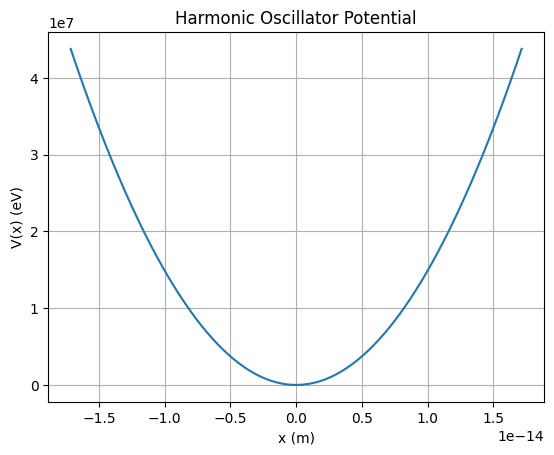

In [ ]:
# plt.plot(x_new, v[1:-1])
# plt.grid()
# plt.title("Harmonic Oscillator Potential")
# plt.xlabel("x (m)")
# plt.ylabel("V(x) (eV)")
# plt.show

## Verify $E_n = (n + \frac{1}{2})\bar{h}\omega$

In [5]:
e_n = h_bar*omega*(np.arange(0, 5) + 1/2)/e  # energy levels in eV
err = e_n - eig_val[0:5]  # error in energy levels

print("For first 5 energy levels:--")
print("\nEnergy levels:", e_n, "eV")
print("Numerical energies:", eig_val[0:5], "eV")
print("Errors:", err)

For first 5 energy levels:--

Energy levels: [ 1758862.5  5276587.5  8794312.5 12312037.5 15829762.5] eV
Numerical energies: [ 1758851.5073108   5276532.54785288  8794169.88573486 12311766.96945933
 15829356.23498384] eV
Errors: [ 10.9926892   54.95214712 142.61426513 270.53054066 406.26501616]


# Normalise 
$\int_{-\infty}^{+\infty} \psi(x) \psi^*(x) dx = A^2$

In [6]:
psi = eig_vec[:, :5]  # first 5 eigenvectors corresponding to the first 5 energy levels
for i in range(5):
    A = np.sqrt( np.trapezoid( psi[:,i]**2 , x_new ) )  # normalization constant
    psi[:,i] = psi[:,i]/A  # normalized wavefunction

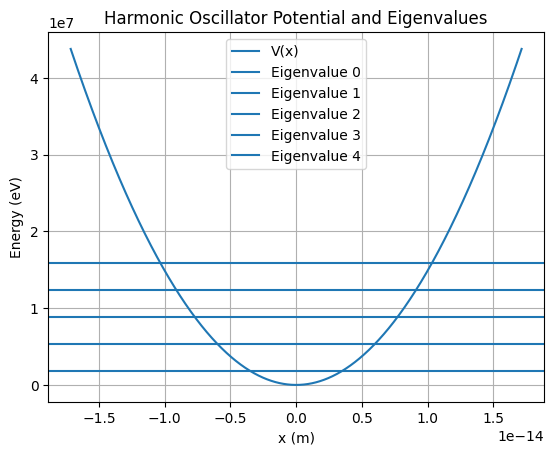

In [8]:
plt.plot(x_new, v[1:-1], label = "V(x)")
for i in range(5):
    plt.axhline(eig_val[i], label = "Eigenvalue {}".format(i))
plt.title("Harmonic Oscillator Potential and Eigenvalues")
plt.xlabel("x (m)")
plt.ylabel("Energy (eV)")
plt.grid()
plt.legend()

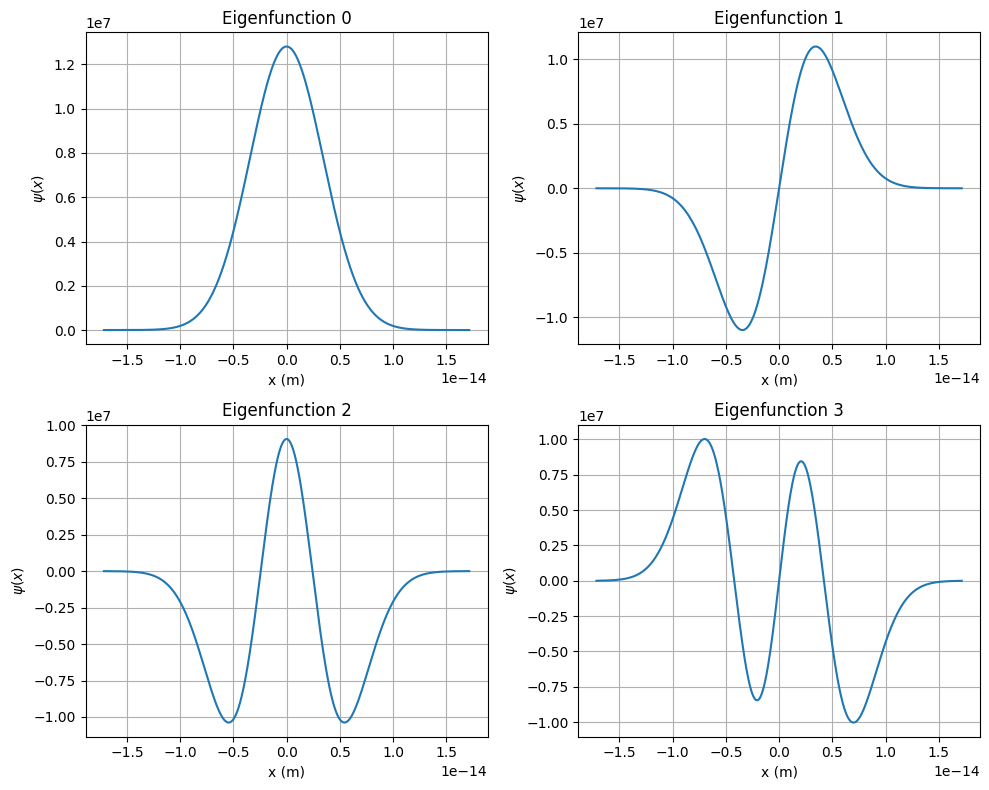

In [9]:
fig, ax = plt.subplots(2, 2, figsize=(10,8))
for i in range(4):
    ax[i//2, i%2].plot(x_new, psi[:,i])
    ax[i//2, i%2].set_title(f'Eigenfunction {i}')
    ax[i//2, i%2].set_xlabel('x (m)')
    ax[i//2, i%2].set_ylabel(r'$\psi(x)$')
    ax[i//2, i%2].grid()

plt.tight_layout()
plt.show()

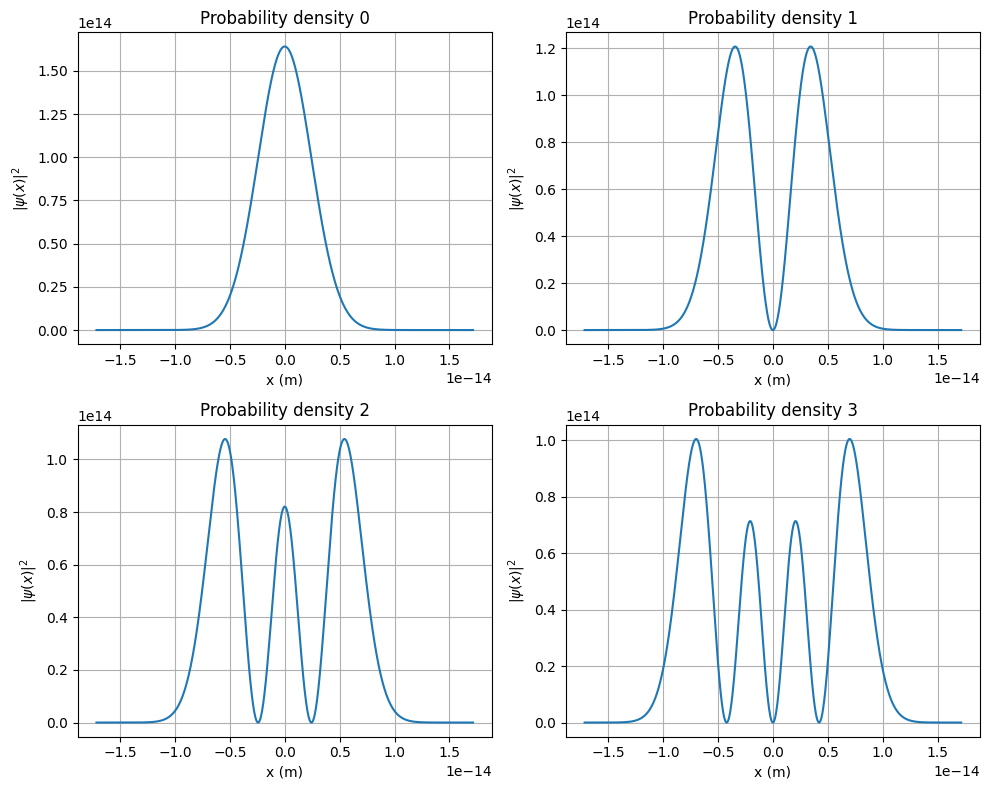

In [10]:
fig, ax = plt.subplots(2, 2, figsize=(10,8))

for i in range(4):
    ax[i//2, i%2].plot(x_new, psi[:,i]**2)
    ax[i//2, i%2].set_title(f'Probability density {i}')
    ax[i//2, i%2].set_xlabel('x (m)')
    ax[i//2, i%2].set_ylabel(r'$|\psi(x)|^2$')
    ax[i//2, i%2].grid()

plt.tight_layout()
plt.show()

In [12]:
count = 3
delx = delta_x

In [14]:
exp_x = np.zeros(count)
exp_x2 = np.zeros(count)
exp_v = np.zeros(count)

# diff_psi = np.zeros((n-3, count))  # shape of diff_psi is (n-3, count)

exp_p = np.zeros(count)
exp_p2 = np.zeros(count)
exp_ke = np.zeros(count)

diff_psi = (psi[1:,:] - psi[:-1,:])/delx  # shape of diff_psi is (n-3, count)
xmid = (x_new[1:] + x_new[:-1])/2  # x_i = (x[i] + x[i+1])/2;  (everything except the first - everything except the last)/2
psi_mid = (psi[1:,:] + psi[:-1,:])/2
#print("this ", diff_psi.shape, psi_mid.shape, xmid.shape)

diff2_psi = (diff_psi[1:,:] - diff_psi[:-1,:])/delx  # shape of diff2_psi is (n-4, count)
psi_mid2 = psi[1:-1,:]  # shape of psi_mid2 is (n-4, count); exclude 1st & last point 
xmid2 = x_new[1:-1]

sigma_x = np.zeros(count)
sigma_p = np.zeros(count)
sigma_xp = np.zeros(count)
 # sigma_x * sigma_p >= h_bar/2 --> (sigma_x * sigma_p)*2/h_bar >= 1

print("Calculating expectation values for state:")
for i in range(count):
    print("\n",i+1,") ")
    yp = x_new* psi[:,i]**2
    # <x> = psi(x)^2 * x
    exp_x[i]= np.trapezoid(yp, x_new)
    
    # <x^2> = psi(x)^2 * x^2
    yp2 = (x_new* psi[:,i])**2
    exp_x2[i] = np.trapezoid(yp2, x_new)
    
    # <V> = psi(x)^2 * V(x)
    yp3 = v[1:-1] * psi[:,i]**2
    #print("yp3 shape: ", yp3.shape, "xnew shape: ", xnew.shape)
    exp_v[i] = np.trapezoid(yp3, x_new)
    
    print("<x> = ", exp_x[i])
    print("<x^2> = ", exp_x2[i])
    print("<V> = ", exp_v[i])
    
    # <p> = -i*h_bar*(psi*(x) d(psi)/dx)
    yp4 = (psi_mid[:,i] * diff_psi[:,i])
    #print("yp4 shape: ", yp4.shape, "xmid shape: ", xmid.shape)
    exp_p[i] = (-1) * h_bar * np.trapezoid(yp4, xmid) 
    print("<p> = ", exp_p[i] * 1j)
    
    # <p^2> = -h_bar^2 *(psi*(x) d2(psi)/dx2)
    yp5 = psi_mid2[:,i]*diff2_psi[:,i]
    exp_p2[i]= np.trapezoid(yp5, xmid2) * (-1 * h_bar**2)
    print("<p^2> = ", exp_p2[i])
    
    # <k> = <p^2>/2m
    exp_ke[i] = exp_p2[i]/(2*reduced_m*e)
    print("<KE> = ", exp_ke[i])
    
    print("Total energy = <KE> + <V> = ", exp_ke[i] + exp_v[i], f"eV = E_{i+1} = ", eig_val[i], "eV")
    
    # Uncertainty in x = sqrt(<x^2> - <x>^2)
    var_x = exp_x2[i] - (exp_x[i]**2)
    sigma_x[i] = np.sqrt(var_x)
    var_p = exp_p2[i] - (exp_p[i]**2)
    sigma_p[i] = np.sqrt(var_p)
    
    sigma_xp[i] = sigma_x[i] * sigma_p[i]
    
print( "Ratio of (sigma_x * sigma_p)/(h_bar/2) :", (2 * sigma_xp/h_bar))

Calculating expectation values for state:

 1 ) 
<x> =  4.4827020939184e-28
<x^2> =  5.909455364981121e-30
<V> =  879420.2538357654
<p> =  (-0+0j)
<p^2> =  4.699680618572048e-40
<KE> =  879431.2534753082
Total energy = <KE> + <V> =  1758851.5073110736 eV = E_1 =  1758851.507310796 eV

 2 ) 
<x> =  3.42286746775397e-27
<x^2> =  1.7728217442461387e-29
<V> =  2638238.6396711273
<p> =  4.88916015625e-37j
<p^2> =  1.4099042645370706e-39
<KE> =  2638293.9081906253
Total energy = <KE> + <V> =  5276532.547861753 eV = E_2 =  5276532.547852879 eV

 3 ) 
<x> =  7.304851982346569e-28
<x^2> =  2.954666476691041e-29
<V> =  4397010.185286278
<p> =  8.234375e-37j
<p^2> =  2.34984214398996e-39
<KE> =  4397159.700580014
Total energy = <KE> + <V> =  8794169.885866292 eV = E_3 =  8794169.885734864 eV
Ratio of (sigma_x * sigma_p)/(h_bar/2) : [0.99999375 2.99996876 4.99991892]
